# B5 — Integrasi: Rangkaian Praproses SIMUTEH
Nama: Try Dymaz Prayoga · NIM 2330511020 · **SEED = 1020**

Kanal evaluasi: **R** (kanal dengan KB tertinggi di Bagian 2, rerata 7,26 pada kelas berat).

In [1]:
import sys, time, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patches as mp
from utils_cv import baca, tampil, kontras_bercak
from praproses import (praproses, praproses_adaptif, deteksi_kondisi,
                       simpan_param, simpan_cfg, muat_param, PARAM_BAWAAN)
KANAL = 2 # indeks BGR: 2 = R (kanal terbaik di Bagian 2)
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
label = pd.read_csv("../data/sintetis/label.csv")
def muat(nama):
    return (baca(f"../data/sintetis/citra/{nama}"),
            cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0),
            cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0))

## Langkah 5.1 Modul `src/praproses.py`
Kelima TODO sudah dilengkapi (ubah ukuran INTER_AREA, gamma LUT, CLAHE kanal V, redam derau, unsharp masking). Modul juga diberi **mode adaptif**: kondisi cahaya dideteksi dari statistik histogram (aturan Bagian 3, P3.5), lalu parameter disesuaikan per kondisi.

In [2]:
# Uji cepat: ukuran tetap 640 x 480, rasio aspek terjaga untuk citra beresolusi lain
img, _, _ = muat("teh_041.png")
print("640x480 ->", praproses(img).shape)
besar = cv2.resize(img, (4000, 3000))
print("4000x3000 ->", praproses(besar).shape)

640x480 -> (480, 640, 3)
4000x3000 -> (480, 640, 3)


## Langkah 5.2 Evaluasi kuantitatif
Tiga rangkaian dibandingkan pada 40 citra berbercak (kelas ringan + berat):
1. **Contoh modul**: parameter contoh Kode 5.2 (gamma 1, CLAHE 2,0, median 3), sebagai pembanding.
2. **Tetap terpilih**: satu set untuk semua kondisi (tanpa CLAHE, median 3).
3. **Adaptif (final)**: dasar = (2), lalu terang → gamma 1,6; bayangan → CLAHE clip 1,0 tile 8.

Parameter (3) dipilih dengan *grid search* (gamma × CLAHE × penajaman) per kondisi, dengan dua syarat: gamma tidak boleh menjauhkan kecerahan dari kondisi normal (citra gelap tidak boleh digelapkan) dan simpangan baku daun sehat tidak boleh naik.

### Grid search pemilihan parameter (bukti Tabel 13)
Untuk setiap kondisi dan dua pilihan penapis, dicoba gamma {0,7; 0,85; 1,0; 1,3; 1,6} × CLAHE clip {0; 1,0; 2,0} × tajam_k {0; 0,5}.
- **syarat arah**: gelap, kontras rendah, bayangan hanya boleh gamma ≤ 1; terang hanya gamma ≥ 1; normal gamma = 1.
- **syarat sehat**: simpangan baku kanal R daun sehat (4 citra sehat kondisi yang sama) tidak boleh naik.

In [3]:
import itertools
ARAH = {"normal": lambda g: g == 1.0, "gelap": lambda g: g <= 1.0, "terang": lambda g: g >= 1.0,
        "kontras_rendah": lambda g: g <= 1.0, "bayangan": lambda g: g <= 1.0}
PENAPIS = {"median3": {"penapis": "median", "kernel": 3},
           "gauss5": {"penapis": "gaussian", "kernel": 5, "sigma": 1.0}}
data = {kd: [(d.kelas, *muat(d.nama_file)) for _, d in label[label.kondisi_cahaya == kd].iterrows()] for kd in URUT}
grid = []
for kd in URUT:
    for pn, g, cl, t in itertools.product(PENAPIS, [0.7, 0.85, 1.0, 1.3, 1.6], [0, 1.0, 2.0], [0, 0.5]):
        p = {"gamma": g, "clahe_clip": cl, "tajam_k": t, **PENAPIS[pn]}
        kb0, kb1, s0, s1 = [], [], [], []
        for kelas, img, md, mb in data[kd]:
            out = praproses(img, p)
            if kelas == "sehat":
                s0.append(img[:, :, KANAL][md > 0].std()); s1.append(out[:, :, KANAL][md > 0].std())
            else:
                kb0.append(kontras_bercak(img[:, :, KANAL], md, mb)); kb1.append(kontras_bercak(out[:, :, KANAL], md, mb))
        grid.append([kd, pn, g, cl, t, np.mean(kb0), np.mean(kb1), np.mean(s0), np.mean(s1)])
grid = pd.DataFrame(grid, columns=["kondisi", "penapis", "gamma", "clahe", "tajam", "KB_asli", "KB", "sd_sehat_asli", "sd_sehat"])
grid["syarat_arah"] = [ARAH[k](g) for k, g in zip(grid.kondisi, grid.gamma)]
grid["syarat_sehat"] = grid.sd_sehat <= grid.sd_sehat_asli
grid.round(3).to_csv("../hasil/b5_grid_parameter.csv", index=False)

lolos = grid[grid.syarat_arah & grid.syarat_sehat]
terbaik = lolos.loc[lolos.groupby(["penapis", "kondisi"]).KB.idxmax()]
print("Terbaik yang memenuhi syarat:")
print(terbaik[["penapis", "kondisi", "gamma", "clahe", "tajam", "KB_asli", "KB", "sd_sehat_asli", "sd_sehat"]].round(2).to_string(index=False))
print("\nRerata KB terbaik per penapis:", terbaik.groupby("penapis").KB.mean().round(2).to_dict())
tanpa = grid.loc[grid.groupby("kondisi").KB.idxmax()]
print("\nTerbaik TANPA syarat (perhatikan gamma pada gelap/bayangan/kontras rendah):")
print(tanpa[["kondisi", "penapis", "gamma", "clahe", "tajam", "KB"]].round(2).to_string(index=False))

Terbaik yang memenuhi syarat:
penapis        kondisi  gamma  clahe  tajam  KB_asli    KB  sd_sehat_asli  sd_sehat
 gauss5       bayangan    1.0    2.0    0.0     5.11 10.04          13.38      9.54
 gauss5          gelap    1.0    1.0    0.5     8.88 14.22          10.16      6.52
 gauss5 kontras_rendah    1.0    0.0    0.0     3.76  9.21          11.01      3.99
 gauss5         normal    1.0    0.0    0.5     8.86 13.27          10.18      7.33
 gauss5         terang    1.6    0.0    0.5     7.25 12.09          12.41      7.98
median3       bayangan    1.0    2.0    0.0     5.11  9.71          13.38      9.86
median3          gelap    1.0    0.0    0.0     8.88 15.26          10.16      5.60
median3 kontras_rendah    1.0    0.0    0.0     3.76  7.81          11.01      4.95
median3         normal    1.0    0.0    0.0     8.86 14.20          10.18      6.59
median3         terang    1.6    0.0    0.0     7.25 12.60          12.41      7.87

Rerata KB terbaik per penapis: {'gauss5': 11.

In [4]:
# Penyederhanaan: pada kondisi gelap CLAHE 1,0 hanya menambah KB sedikit, jadi tidak dipakai
g = grid[(grid.penapis == "median3") & (grid.kondisi == "gelap") & (grid.gamma == 1.0) & (grid.tajam == 0)]
print(g[["clahe", "KB", "sd_sehat"]].round(2).to_string(index=False))

 clahe    KB  sd_sehat
   0.0 15.26      5.60
   1.0 14.84      6.38
   2.0 13.72      7.23


In [5]:
# Kode 5.2 dengan parameter contoh modul (disimpan terpisah sebagai pembanding)
param_contoh = {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3}
simpan_param(param_contoh, "../hasil/param_contoh_modul.json")

param_tetap = {"gamma": 1.0, "clahe_clip": 0, "penapis": "median", "kernel": 3, "tajam_k": 0.0}
CFG = {
    "kanal_evaluasi": "R",
    "dasar": param_tetap,
    "per_kondisi": {
        "terang": {"gamma": 1.6},
        "bayangan": {"clahe_clip": 1.0, "clahe_tile": 8},
    },
    "ambang": {"bayangan_lr": 40, "terang_rerata": 190, "kontras_std": 25, "gelap_rerata": 145},
}
simpan_cfg(CFG, "../hasil/param_praproses.json")
print(json.dumps(muat_param("../hasil/param_praproses.json"), indent=2))

{
  "kanal_evaluasi": "R",
  "dasar": {
    "gamma": 1.0,
    "clahe_clip": 0,
    "penapis": "median",
    "kernel": 3,
    "tajam_k": 0.0
  },
  "per_kondisi": {
    "terang": {
      "gamma": 1.6
    },
    "bayangan": {
      "clahe_clip": 1.0,
      "clahe_tile": 8
    }
  },
  "ambang": {
    "bayangan_lr": 40,
    "terang_rerata": 190,
    "kontras_std": 25,
    "gelap_rerata": 145
  }
}


In [6]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    a = praproses(img, param_contoh)
    b = praproses(img, param_tetap)
    t0 = time.perf_counter(); c_, kd = praproses_adaptif(img, CFG); dt = 1000 * (time.perf_counter() - t0)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, kd,
                  kontras_bercak(img[:, :, KANAL], md, mb),
                  kontras_bercak(a[:, :, KANAL], md, mb),
                  kontras_bercak(b[:, :, KANAL], md, mb),
                  kontras_bercak(c_[:, :, KANAL], md, mb), dt])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "kondisi_terdeteksi", "KB_sebelum",
                                  "KB_contoh_modul", "KB_tetap", "KB_adaptif", "waktu_ms"])
print("Deteksi kondisi benar:", (ev.kondisi == ev.kondisi_terdeteksi).mean())
print(f"Waktu praproses adaptif: rerata {ev.waktu_ms.mean():.2f} ms per citra 640x480")
banding = ev.groupby("kondisi")[["KB_sebelum", "KB_contoh_modul", "KB_tetap", "KB_adaptif"]].mean().loc[URUT].round(2)
banding.loc["rerata"] = banding.mean().round(2)
print(banding)
ev.to_csv("../hasil/b5_evaluasi_per_citra.csv", index=False)

Deteksi kondisi benar: 1.0
Waktu praproses adaptif: rerata 1.21 ms per citra 640x480
                KB_sebelum  KB_contoh_modul  KB_tetap  KB_adaptif
kondisi                                                          
normal                8.86            10.79     14.20       14.20
gelap                 8.88            13.72     15.26       15.26
terang                7.25             6.35     11.32       12.60
kontras_rendah        3.76             4.71      7.81        7.81
bayangan              5.11             9.71      7.01        9.40
rerata                6.77             9.06     11.12       11.85


### Tabel 12. Evaluasi rangkaian praproses final (adaptif)

                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
normal                8.86       14.20        60.34
gelap                 8.88       15.26        71.80
terang                7.25       12.60        73.83
kontras_rendah        3.76        7.81       107.73
bayangan              5.11        9.40        83.95


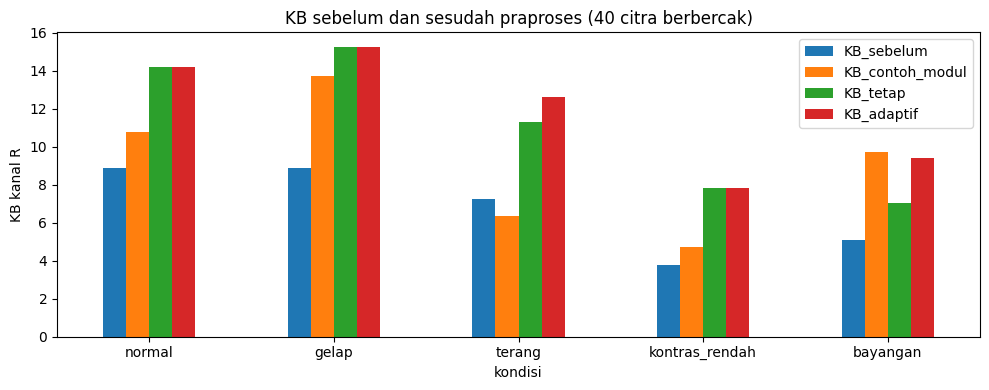

In [7]:
tabel12 = ev.groupby("kondisi")[["KB_sebelum", "KB_adaptif"]].mean().loc[URUT]
tabel12.columns = ["KB_sebelum", "KB_sesudah"]
tabel12["perubahan_%"] = 100 * (tabel12.KB_sesudah - tabel12.KB_sebelum) / tabel12.KB_sebelum
tabel12 = tabel12.round(2); print(tabel12)
tabel12.to_csv("../hasil/b5_tabel12.csv")

ax = banding.drop("rerata")[["KB_sebelum", "KB_contoh_modul", "KB_tetap", "KB_adaptif"]].plot.bar(figsize=(10, 4))
ax.set_ylabel("KB kanal R"); ax.set_title("KB sebelum dan sesudah praproses (40 citra berbercak)")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("../hasil/b5_kb_praproses.png", dpi=120); plt.show()

In [8]:
# Cek generalisasi sederhana: per kelas (ringan vs berat)
print(ev.groupby(["kelas", "kondisi"])[["KB_sebelum", "KB_adaptif"]].mean().round(2).unstack(0))
print("\nJumlah citra yang KB-nya turun:", (ev.KB_adaptif < ev.KB_sebelum).sum(), "dari", len(ev))

               KB_sebelum        KB_adaptif       
kelas               berat ringan      berat ringan
kondisi                                           
bayangan             6.03   4.19      11.30   7.50
gelap               10.52   7.24      18.12  12.40
kontras_rendah       4.11   3.40       8.62   6.99
normal               9.07   8.64      15.11  13.30
terang               6.92   7.58      12.66  12.54

Jumlah citra yang KB-nya turun: 0 dari 40


## Langkah 5.3 Uji bercak palsu pada kelas sehat (teh_001 s.d. teh_020)
Simpangan baku kanal R pada area daun dihitung sebelum dan sesudah praproses. Daun sehat tidak punya bercak, sehingga kenaikan simpangan baku berarti praproses menimbulkan variasi yang dapat terbaca sebagai bercak palsu.

In [9]:
bs = []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, _ = muat(d.nama_file)
    daun = md > 0
    a = praproses(img, param_contoh)
    c_, _ = praproses_adaptif(img, CFG)
    bs.append([d.kondisi_cahaya, img[:, :, KANAL][daun].std(),
               a[:, :, KANAL][daun].std(), c_[:, :, KANAL][daun].std()])
sehat = pd.DataFrame(bs, columns=["kondisi", "std_sebelum", "std_contoh_modul", "std_adaptif"])
uji_sehat = sehat.groupby("kondisi").mean().loc[URUT].round(2)
uji_sehat["perubahan_adaptif_%"] = (100 * (uji_sehat.std_adaptif - uji_sehat.std_sebelum) / uji_sehat.std_sebelum).round(1)
print(uji_sehat); uji_sehat.to_csv("../hasil/b5_uji_bercak_palsu.csv")

                std_sebelum  std_contoh_modul  std_adaptif  perubahan_adaptif_%
kondisi                                                                        
normal                10.18              8.58         6.59                -35.3
gelap                 10.16              7.23         5.60                -44.9
terang                12.41             12.77         7.87                -36.6
kontras_rendah        11.01             10.61         4.95                -55.0
bayangan              13.38              9.86         9.04                -32.4


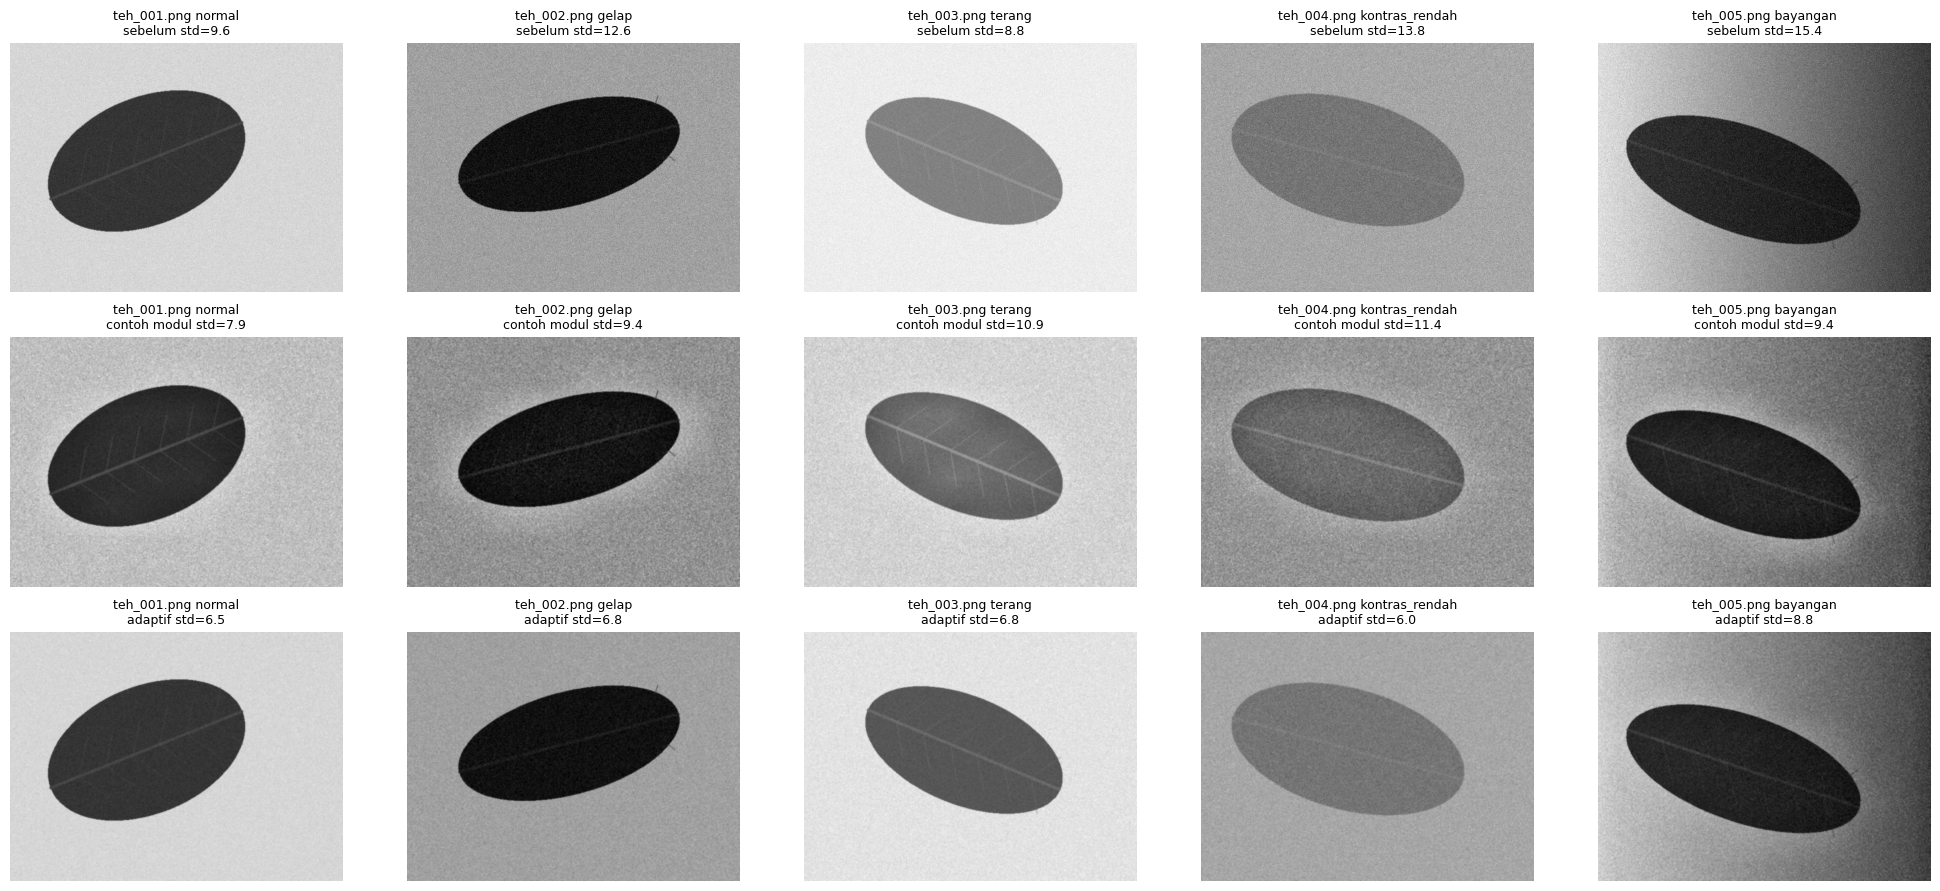

In [10]:
# Panel sebelum dan sesudah, satu citra sehat per kondisi (teh_001..teh_005), kanal R
fig, ax = plt.subplots(3, 5, figsize=(20, 9))
for j, nama in enumerate([f"teh_{i:03d}.png" for i in range(1, 6)]):
    img, md, _ = muat(nama)
    a = praproses(img, param_contoh); c_, kd = praproses_adaptif(img, CFG)
    for i, (x, jd) in enumerate([(img, "sebelum"), (a, "contoh modul"), (c_, "adaptif")]):
        ax[i, j].imshow(x[:, :, KANAL], cmap="gray", vmin=0, vmax=255)
        ax[i, j].set_title(f"{nama} {kd}\n{jd} std={x[:, :, KANAL][md > 0].std():.1f}", fontsize=9); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig("../hasil/b5_uji_bercak_palsu.png", dpi=100); plt.show()

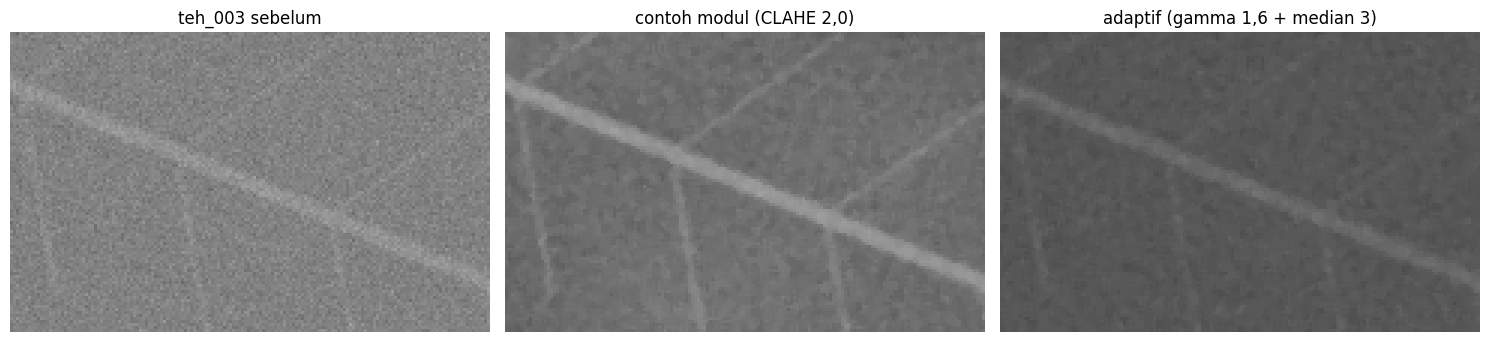

In [11]:
# Perbesar area daun sehat kondisi terang (teh_003): cari titik terang yang dapat dikira bercak
img, md, _ = muat("teh_003.png")
a = praproses(img, param_contoh); c_, _ = praproses_adaptif(img, CFG)
ys, xs = np.where(md > 0); cy, cx = int(ys.mean()), int(xs.mean())
pot = lambda x: cv2.resize(x[cy-50:cy+50, cx-80:cx+80, KANAL], None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST)
tampil([pot(img), pot(a), pot(c_)], ["teh_003 sebelum", "contoh modul (CLAHE 2,0)", "adaptif (gamma 1,6 + median 3)"], ukuran=(15, 3.6))
plt.savefig("../hasil/b5_zoom_sehat_terang.png", dpi=110); plt.show()

### Ablasi penajaman (bukti Tabel 13, langkah 5)
Rangkaian adaptif final dijalankan ulang dengan tajam_k = 0; 0,5; 1,0 untuk melihat pengaruh penajaman pada KB citra berbercak dan pada keragaman daun sehat.

In [12]:
ab = []
for k in [0.0, 0.5, 1.0]:
    cfg_k = {**CFG, "dasar": {**CFG["dasar"], "tajam_k": k}}
    kb, sd = [], []
    for _, d in label.iterrows():
        img, md, mb = muat(d.nama_file)
        out, _ = praproses_adaptif(img, cfg_k)
        if d.kelas == "sehat":
            sd.append(out[:, :, KANAL][md > 0].std())
        else:
            kb.append(kontras_bercak(out[:, :, KANAL], md, mb))
    ab.append([k, np.mean(kb), np.mean(sd)])
ablasi = pd.DataFrame(ab, columns=["tajam_k", "KB_rerata_40_berbercak", "std_daun_sehat_rerata"]).round(2)
print(ablasi); ablasi.to_csv("../hasil/b5_ablasi_tajam.csv", index=False)

   tajam_k  KB_rerata_40_berbercak  std_daun_sehat_rerata
0      0.0                   11.85                   6.81
1      0.5                   11.25                   7.35
2      1.0                   10.33                   8.14


## Langkah 5.4 Diagram rangkaian praproses dengan parameter final

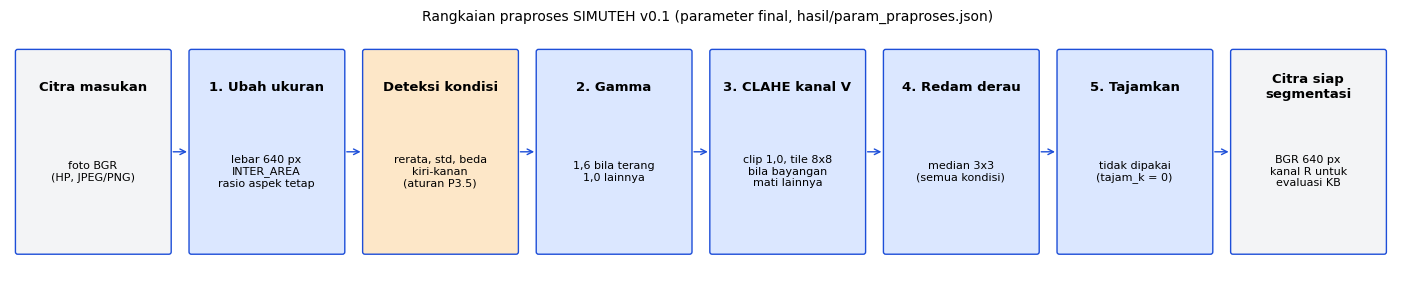

In [13]:
tahap = [
 ("Citra masukan", "foto BGR\n(HP, JPEG/PNG)"),
 ("1. Ubah ukuran", "lebar 640 px\nINTER_AREA\nrasio aspek tetap"),
 ("Deteksi kondisi", "rerata, std, beda\nkiri-kanan\n(aturan P3.5)"),
 ("2. Gamma", "1,6 bila terang\n1,0 lainnya"),
 ("3. CLAHE kanal V", "clip 1,0, tile 8x8\nbila bayangan\nmati lainnya"),
 ("4. Redam derau", "median 3x3\n(semua kondisi)"),
 ("5. Tajamkan", "tidak dipakai\n(tajam_k = 0)"),
 ("Citra siap\nsegmentasi", "BGR 640 px\nkanal R untuk\nevaluasi KB"),
]
fig, ax = plt.subplots(figsize=(18, 3.2)); ax.set_xlim(0, 18); ax.set_ylim(0, 3.2); ax.axis("off")
for i, (jd, isi) in enumerate(tahap):
    x = 0.1 + i * 2.24
    warna = "#fde7c8" if jd == "Deteksi kondisi" else ("#dbe7ff" if 0 < i < 7 else "#f3f4f6")
    ax.add_patch(mp.FancyBboxPatch((x, 0.3), 1.95, 2.6, boxstyle="round,pad=0.03", fc=warna, ec="#1d4ed8"))
    ax.text(x + 0.97, 2.45, jd, ha="center", va="center", fontsize=9.5, fontweight="bold")
    ax.text(x + 0.97, 1.35, isi, ha="center", va="center", fontsize=8)
    if i < len(tahap) - 1:
        ax.annotate("", xy=(x + 2.22, 1.6), xytext=(x + 1.97, 1.6), arrowprops=dict(arrowstyle="->", color="#1d4ed8"))
ax.set_title("Rangkaian praproses SIMUTEH v0.1 (parameter final, hasil/param_praproses.json)", fontsize=10)
plt.savefig("../hasil/b5_diagram_praproses.png", dpi=150, bbox_inches="tight"); plt.show()

## Langkah 5.5 Reprodusibilitas

In [14]:
import platform, skimage, matplotlib
print("Python", platform.python_version(), "| OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| pandas", pd.__version__, "| scikit-image", skimage.__version__, "| matplotlib", matplotlib.__version__)
print("SEED dataset = 1020 (src/buat_dataset_sintetis.py), SEED derau B4 = 42")

Python 3.13.5 | OpenCV 4.13.0 | NumPy 2.3.5 | pandas 2.2.3 | scikit-image 0.26.0 | matplotlib 3.10.8
SEED dataset = 1020 (src/buat_dataset_sintetis.py), SEED derau B4 = 42
